In [1]:
!pip install -q deepface opencv-python-headless matplotlib seaborn

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from deepface import DeepFace

print("Libraries imported successfully!")

26-11-07 18:25:11 - Directory /root/.deepface has been created
26-11-07 18:25:11 - Directory /root/.deepface/weights has been created
Libraries imported successfully!


Saving happy_img.jpeg to happy_img.jpeg


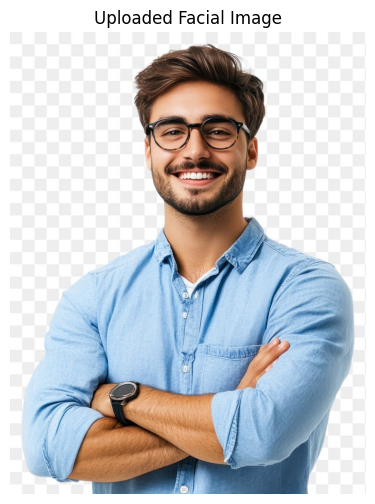

In [3]:
from google.colab import files
from PIL import Image
import io

uploaded = files.upload()

filename = next(iter(uploaded))

image = Image.open(
    io.BytesIO(uploaded[filename])
).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Facial Image")
plt.show()

In [4]:
img_array = np.array(image)

print("Image shape:", img_array.shape)
print("Image loaded successfully!")

Image shape: (1039, 800, 3)
Image loaded successfully!


In [5]:
result = DeepFace.analyze(
    img_path=img_array,
    actions=['emotion'],
    detector_backend='opencv',
    enforce_detection=True,
    silent=True
)

print("EMOTION DETECTION RESULTS")
print("=" * 50)

for i, face in enumerate(result):

    print(f"\nFace {i+1}")
    print("Dominant Emotion:", face['dominant_emotion'])

    print("\nEmotion Confidence Scores:")

    for emotion, score in face['emotion'].items():
        print(f"{emotion}: {score:.2f}%")

26-11-07 18:30:51 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 124MB/s]


EMOTION DETECTION RESULTS

Face 1
Dominant Emotion: happy

Emotion Confidence Scores:
angry: 0.00%
disgust: 0.00%
fear: 0.00%
happy: 86.58%
sad: 0.00%
surprise: 0.06%
neutral: 13.36%


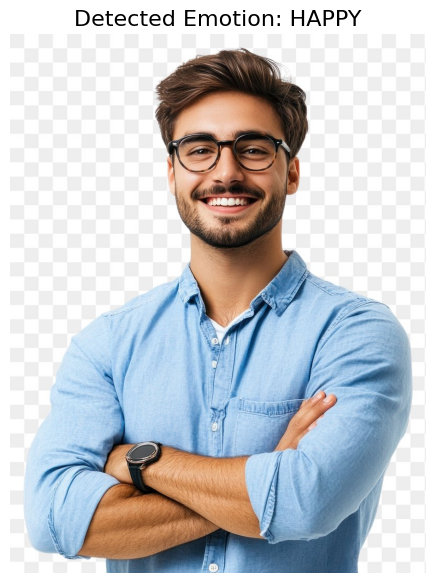

Predicted Emotion: happy


In [6]:
dominant_emotion = result[0]['dominant_emotion']

plt.figure(figsize=(7, 7))
plt.imshow(image)

plt.title(
    f"Detected Emotion: {dominant_emotion.upper()}",
    fontsize=16
)

plt.axis("off")
plt.show()

print("Predicted Emotion:", dominant_emotion)

In [8]:
def cognitive_assistant(emotion):

    responses = {
        'happy': "You appear to be smiling! Keep spreading positivity.",
        'sad': "You appear to have a sad expression. Would you like some encouragement?",
        'angry': "You appear to have an angry expression. Take a moment to relax.",
        'fear': "You appear to have a worried expression. Take a deep breath.",
        'surprise': "You appear surprised! Something unexpected?",
        'disgust': "You appear to be showing displeasure. Would you like to take a break?",
        'neutral': "Your facial expression appears neutral. How can I help you?"
    }

    return responses.get(
        emotion.lower(),
        "Unable to recognize the expression."
    )


print("COGNITIVE ASSISTANT")
print("=" * 50)

print("Detected Expression:", dominant_emotion)
print("Assistant:", cognitive_assistant(dominant_emotion))

COGNITIVE ASSISTANT
Detected Expression: happy
Assistant: You appear to be smiling! Keep spreading positivity.


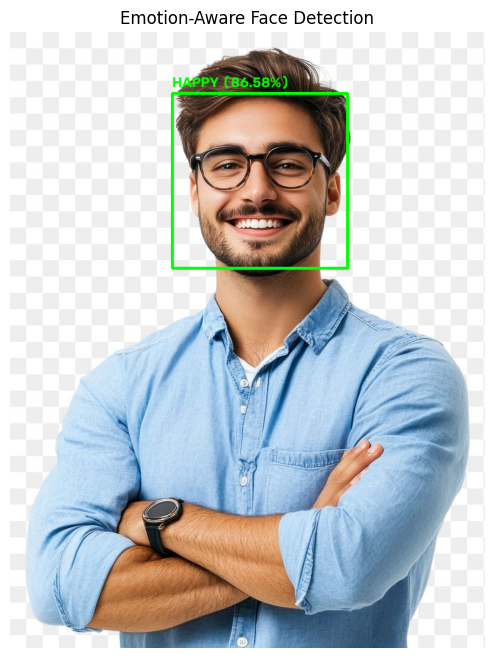

In [9]:
# Get face coordinates
face_region = result[0]['region']

x = face_region['x']
y = face_region['y']
w = face_region['w']
h = face_region['h']

# Convert image to OpenCV format
display_img = cv2.cvtColor(
    img_array.copy(),
    cv2.COLOR_RGB2BGR
)

# Draw bounding box
cv2.rectangle(
    display_img,
    (x, y),
    (x + w, y + h),
    (0, 255, 0),
    3
)

# Add emotion label
label = f"{dominant_emotion.upper()} ({result[0]['emotion'][dominant_emotion]:.2f}%)"

cv2.putText(
    display_img,
    label,
    (x, max(y - 10, 25)),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (0, 255, 0),
    2
)

# Display result
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB))
plt.title("Emotion-Aware Face Detection")
plt.axis("off")
plt.show()